Predict future averge price of Pulses and Nuts monthly in Yangon by using SARIMAX model and Linear Regression Model
* According to the result, SARIMAX is better. But we can't tell exactly because of the causes of Covid 19 and Political changes

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2011-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2012-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DPNM_Y = data.copy()
mask = (DPNM_Y['category']=='pulses and nuts') & (DPNM_Y['region']=='Yangon')
DPNM_Y = DPNM_Y.loc[mask]
DPNM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
4082,1/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1820.00,1.0225
4337,2/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1820.00,1.0225
4613,3/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1750.00,0.9831
4880,4/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1732.98,0.9736
5141,5/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1653.61,0.9290


In [13]:
obv_st_date = pd.to_datetime("2011-01-01")

In [14]:
DPNM_Y = DPNM_Y[['date', 'price']]
DPNM_Y['date'] = pd.to_datetime(DPNM_Y['date'])
mask = (DPNM_Y['date']>=obv_st_date) & (DPNM_Y['date']<=obv_end_date)
DPNM_Y = DPNM_Y.loc[mask]
DPNM_Y = DPNM_Y.set_index('date')
DPNM_Y.head()

,price
date,
2011-01-15,1820.00
2011-02-15,1820.00
2011-03-15,1750.00
2011-04-15,1732.98
2011-05-15,1653.61


In [15]:
DPNM_Y = DPNM_Y.resample('MS').mean()
DPNM_Y.head()

,price
date,
2011-01-01,1820.00
2011-02-01,1820.00
2011-03-01,1750.00
2011-04-01,1732.98
2011-05-01,1653.61


In [16]:
DPNM_Y.shape

(133, 1)

In [17]:
price = DPNM_Y['price']
date = DPNM_Y.index

##### Normalization data

In [18]:
scaler = MinMaxScaler()

In [19]:
DPNM_Y_nor = scaler.fit_transform(DPNM_Y)
DPNM_Y_nor = pd.DataFrame(DPNM_Y_nor)
DPNM_Y_nor.head()

,0
0,0.263020
1,0.263020
2,0.233159
3,0.225899
4,0.192041


In [20]:
DPNM_Y_nor['date']=date
DPNM_Y_nor = DPNM_Y_nor.set_index('date')
DPNM_Y_nor.columns=['price']
DPNM_Y_nor.head()

,price
date,
2011-01-01,0.263020
2011-02-01,0.263020
2011-03-01,0.233159
2011-04-01,0.225899
2011-05-01,0.192041


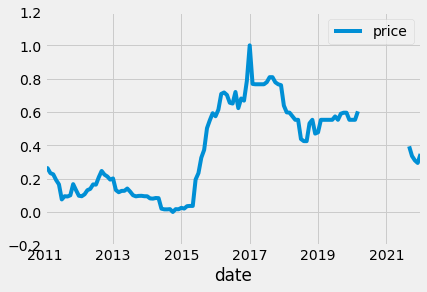

In [21]:
DPNM_Y_nor.plot(grid=True)
plt.show()

It has some missing data.

In [22]:
DPNM_Y_nor = DPNM_Y_nor.interpolate(method="linear")
DPNM_Y.shape

(133, 1)

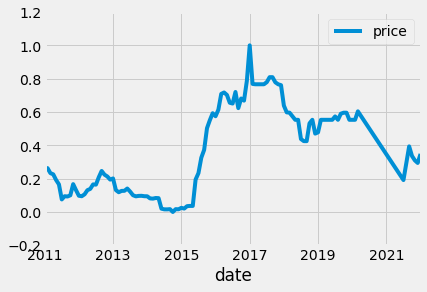

In [23]:
DPNM_Y_nor.plot(grid=True)
plt.show()

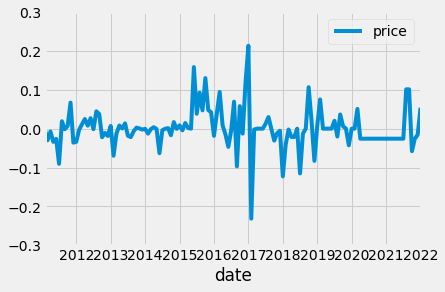

In [24]:
DPNM_Y_nor_diff1 = DPNM_Y_nor.diff(1).dropna()
DPNM_Y_nor_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [25]:
RW_DPNM_Y= adfuller(DPNM_Y_nor_diff1)
RW_DPNM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

0.00774554801148749

##### Plotting ACF and PACF

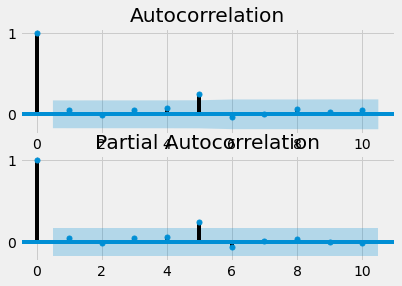

In [26]:
fig, axes=plt.subplots(2,1)
plot_acf(DPNM_Y_nor_diff1, lags=10, ax=axes[0])
plot_pacf(DPNM_Y_nor_diff1, lags=10, ax=axes[1])
plt.show()

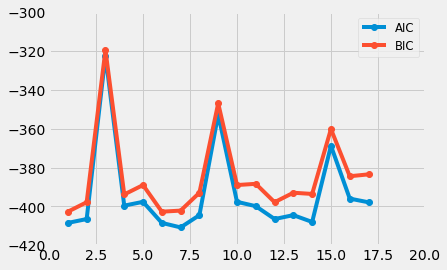

In [27]:
AIC, BIC = AIC_BIC_withOrderRange(DPNM_Y_nor_diff1, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [28]:
AIC, BIC

(array([-410.15315269, -408.48030761, -406.49744445, -322.4301193 ,
        -399.59128679, -397.64142343, -408.47335608, -410.79923599,
        -404.49370721, -352.7230895 , -397.63587054, -399.87617939,
        -406.48470126, -404.48818021, -407.99792374, -368.82113188,
        -395.97737492, -397.88009398]),
 array([-407.27035077, -402.71470377, -397.84903868, -319.55492198,
        -393.84089215, -389.01583146, -402.70775223, -402.15083022,
        -392.96249952, -346.97269485, -389.01027857, -388.3753901 ,
        -397.83629549, -392.95697252, -393.58391413, -360.19553991,
        -384.47658563, -383.50410736]))

We will run again 1:(0,0,1), 6:(1,0,0), 12:(2,0,0), 14:(2,0,2),

In [29]:
mod_orders = [
    (0,0,1), 
    (1,0,0), 
    (2,0,0), 
    (2,0,2),
]

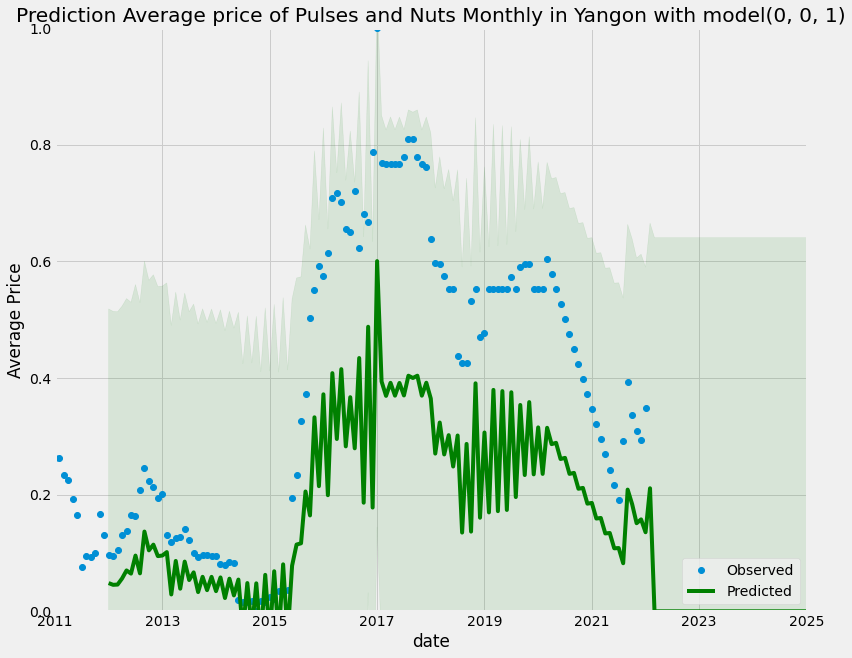

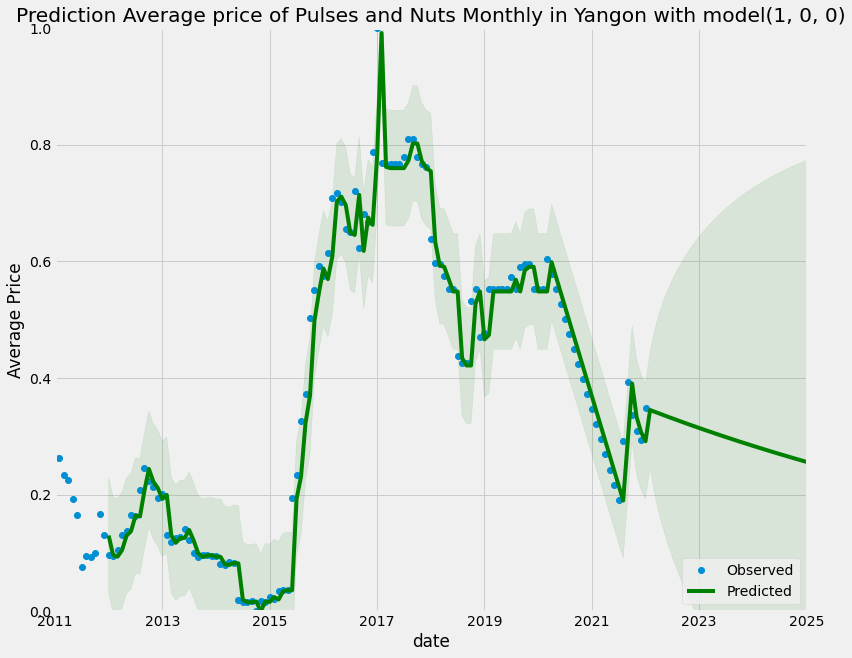

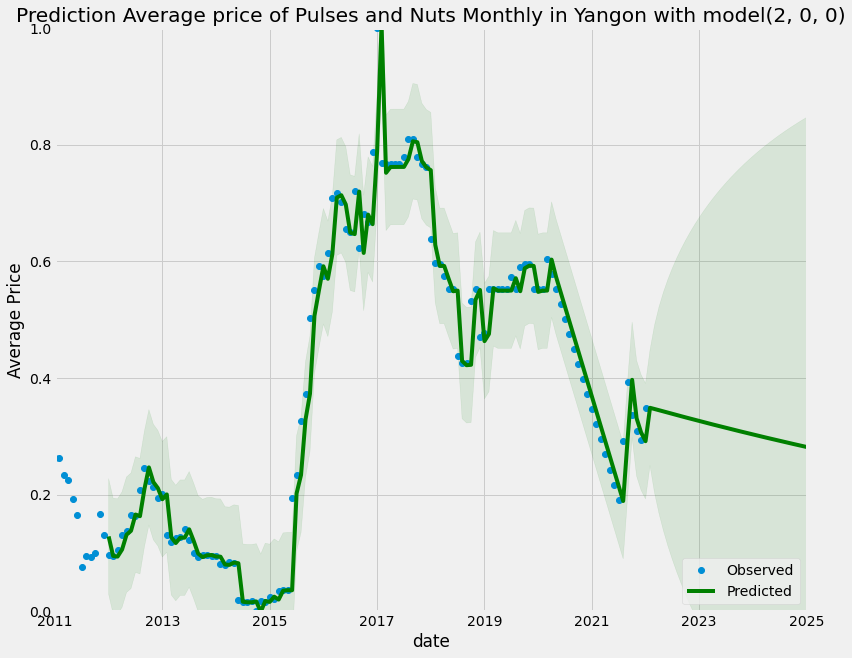

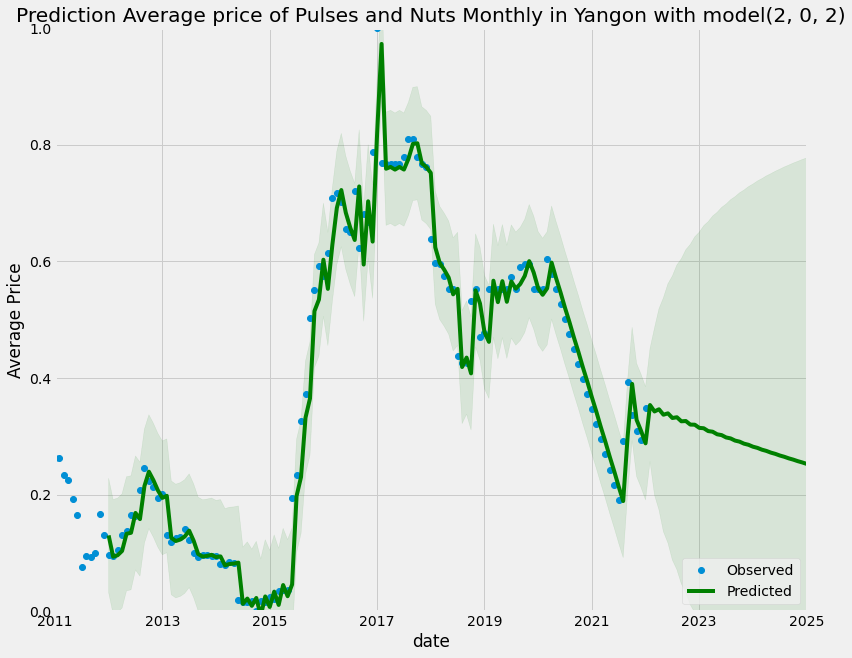

In [30]:
DPNM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DPNM_Y_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Pulses and Nuts Monthly in Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DPNM_Y_models.append(model)

Now we choose (1, 0, 0)

In [31]:
DPNM_Y_model = DPNM_Y_models[1]

In [32]:
DPNM_Y_pred_normalized = DPNM_Y_model.predict(pred_st_date, pred_end_date)
DPNM_Y_pred_normalized

2012-01-01    0.129944
2012-02-01    0.096458
2012-03-01    0.093704
2012-04-01    0.105006
2012-05-01    0.129635
                ...   
2024-09-01    0.265006
2024-10-01    0.262757
2024-11-01    0.260528
2024-12-01    0.258317
2025-01-01    0.256125
Freq: MS, Length: 157, dtype: float64

In [33]:
mask = (DPNM_Y_nor.index>=pred_st_date) & (DPNM_Y_nor.index<=pred_end_date)
DPNM_Y_pred = DPNM_Y_nor.loc[mask]
DPNM_Y_pred

,price
date,
2012-01-01,0.097283
2012-02-01,0.094506
2012-03-01,0.105904
2012-04-01,0.130745
2012-05-01,0.138453
...,...
2021-09-01,0.393847
2021-10-01,0.335967
2021-11-01,0.309870


We need to un-normalized the predicted value to get actual price

In [34]:
pred_date = DPNM_Y_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2012-01-01', '2012-02-01', '2012-03-01', '2012-04-01',
               '2012-05-01', '2012-06-01', '2012-07-01', '2012-08-01',
               '2012-09-01', '2012-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=156, freq='MS')

In [35]:
DPNM_Y_pred_normalized_df = pd.DataFrame(DPNM_Y_pred_normalized)
DPNM_Y_pred_normalized_df = DPNM_Y_pred_normalized_df[:-1] # the last index doesn't need
DPNM_Y_pred_normalized_df

,0
2012-01-01,0.129944
2012-02-01,0.096458
2012-03-01,0.093704
2012-04-01,0.105006
2012-05-01,0.129635
...,...
2024-08-01,0.267274
2024-09-01,0.265006
2024-10-01,0.262757
2024-11-01,0.260528


##### Un-normalization data

In [36]:
DPNM_Y_pred_act = scaler.inverse_transform(DPNM_Y_pred_normalized_df)
DPNM_Y_pred_act_df = pd.DataFrame(DPNM_Y_pred_act)
DPNM_Y_pred_act_df['date'] = pred_date
DPNM_Y_pred_act_df.columns = ['Predicted Price', 'date']
DPNM_Y_pred_act_df.set_index('date',  inplace=True)
DPNM_Y_pred_act_df

,Predicted Price
date,
2012-01-01,1508.043169
2012-02-01,1429.544945
2012-03-01,1423.090183
2012-04-01,1449.583458
2012-05-01,1507.319364
...,...
2024-08-01,1829.970428
2024-09-01,1824.654092
2024-10-01,1819.382867


In [37]:
mask = (DPNM_Y.index>=pred_st_date) & (DPNM_Y.index<=pred_end_date)
DPNM_Y_Act = DPNM_Y.loc[mask]
DPNM_Y_Act

,price
date,
2012-01-01,1431.4800
2012-02-01,1424.9700
2012-03-01,1451.6900
2012-04-01,1509.9200
2012-05-01,1527.9900
...,...
2021-09-01,2126.6825
2021-10-01,1991.0000
2021-11-01,1929.8240


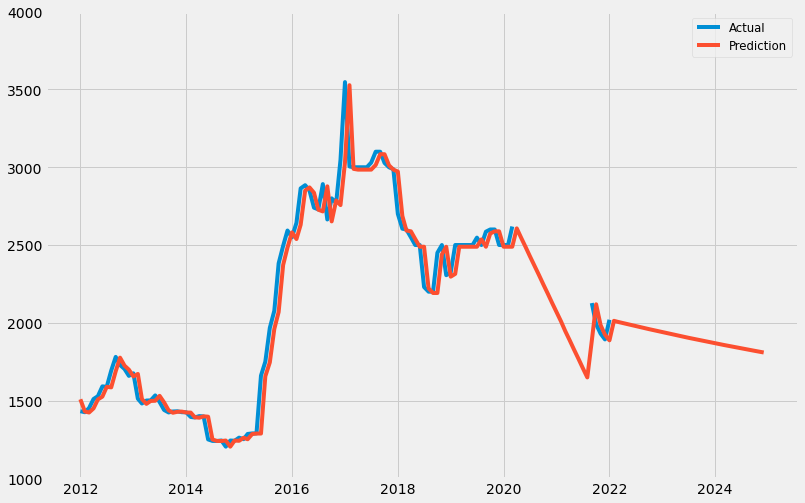

In [38]:
plt.figure(figsize=(12,8))
plt.plot(DPNM_Y_Act, label="Actual")
plt.plot(DPNM_Y_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [39]:
temp_df = DPNM_Y_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2011-01-01,0.263020
1,2011-02-01,0.263020
2,2011-03-01,0.233159
3,2011-04-01,0.225899
4,2011-05-01,0.192041
...,...,...
128,2021-09-01,0.393847
129,2021-10-01,0.335967
130,2021-11-01,0.309870
131,2021-12-01,0.294206


In [40]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2011-01-01  0.263020  1293840000000000000
 1   2011-02-01  0.263020  1296518400000000000
 2   2011-03-01  0.233159  1298937600000000000
 3   2011-04-01  0.225899  1301616000000000000
 5   2011-06-01  0.165759  1306886400000000000
 ..         ...       ...                  ...
 128 2021-09-01  0.393847  1630454400000000000
 129 2021-10-01  0.335967  1633046400000000000
 130 2021-11-01  0.309870  1635724800000000000
 131 2021-12-01  0.294206  1638316800000000000
 132 2022-01-01  0.348082  1640995200000000000
 
 [104 rows x 3 columns],
           date     price                 time
 4   2011-05-01  0.192041  1304208000000000000
 9   2011-10-01  0.100060  1317427200000000000
 10  2011-11-01  0.167068  1320105600000000000
 11  2011-12-01  0.131056  1322697600000000000
 14  2012-03-01  0.105904  1330560000000000000
 21  2012-10-01  0.224022  1349049600000000000
 23  2012-12-01  0.194225  1354320000000000000
 33  2013-10-01  0.096481  138058

In [41]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1293840000000000000],
        [1296518400000000000],
        [1298937600000000000],
        [1301616000000000000],
        [1306886400000000000],
        [1309478400000000000],
        [1312156800000000000],
        [1314835200000000000],
        [1325376000000000000],
        [1328054400000000000]], dtype=int64),
 array([0.26302049, 0.26302049, 0.23315943, 0.22589892, 0.16575875,
        0.07532239, 0.09448466, 0.09294042, 0.09728307, 0.09450599]))

In [42]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1304208000000000000],
        [1317427200000000000],
        [1320105600000000000],
        [1322697600000000000],
        [1330560000000000000],
        [1349049600000000000],
        [1354320000000000000],
        [1380585600000000000],
        [1388534400000000000],
        [1391212800000000000]], dtype=int64),
 array([0.19204075, 0.10006015, 0.16706837, 0.13105593, 0.10590438,
        0.22402194, 0.19422487, 0.09648109, 0.09421591, 0.08141832]))

In [43]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [44]:
DPNM_Y_linreg = LinearRegression().fit(X_train, y_train)

In [45]:
print('linear model coeff or slope (w): {}'.format(DPNM_Y_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DPNM_Y_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DPNM_Y_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DPNM_Y_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [1.21011304e-18]
linear model intercept (b): -1.401
R-squared score (training): 0.259
R-squared score (test): 0.345


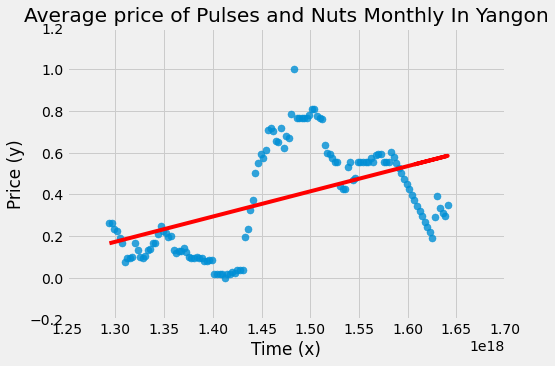

In [46]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DPNM_Y_linreg.coef_ * X + DPNM_Y_linreg.intercept_, 'r-')
plt.title('Average price of Pulses and Nuts Monthly In Yangon')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [47]:
DPNM_Y_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DPNM_Y_linear_predict['time'] = DPNM_Y_linear_predict['date'].apply(lambda x: x.value)
DPNM_Y_linear_predict

,date,time
0,2012-01-01,1325376000000000000
1,2012-02-01,1328054400000000000
2,2012-03-01,1330560000000000000
3,2012-04-01,1333238400000000000
4,2012-05-01,1335830400000000000
...,...,...
152,2024-09-01,1725148800000000000
153,2024-10-01,1727740800000000000
154,2024-11-01,1730419200000000000
155,2024-12-01,1733011200000000000


In [48]:
time_predict = np.array(DPNM_Y_linear_predict['time']).reshape((-1, 1))
DPNM_Y_linear_predict['price'] = DPNM_Y_linreg.predict(time_predict)
DPNM_Y_linear_predict

,date,time,price
0,2012-01-01,1325376000000000000,0.203075
1,2012-02-01,1328054400000000000,0.206316
2,2012-03-01,1330560000000000000,0.209348
3,2012-04-01,1333238400000000000,0.212589
4,2012-05-01,1335830400000000000,0.215726
...,...,...,...
152,2024-09-01,1725148800000000000,0.686845
153,2024-10-01,1727740800000000000,0.689982
154,2024-11-01,1730419200000000000,0.693223
155,2024-12-01,1733011200000000000,0.696359


In [49]:
DPNM_Y_linear_normalized_predict = DPNM_Y_linear_predict.copy()
DPNM_Y_linear_normalized_predict = DPNM_Y_linear_normalized_predict[['date', 'price']]
DPNM_Y_linear_normalized_predict.set_index('date', inplace=True)
DPNM_Y_linear_normalized_predict

,price
date,
2012-01-01,0.203075
2012-02-01,0.206316
2012-03-01,0.209348
2012-04-01,0.212589
2012-05-01,0.215726
...,...
2024-09-01,0.686845
2024-10-01,0.689982
2024-11-01,0.693223


##### Unnormalized the data

In [50]:
DPNM_Y_pred_act_linear = scaler.inverse_transform(DPNM_Y_linear_normalized_predict)
DPNM_Y_pred_act_linear_df = pd.DataFrame(DPNM_Y_pred_act_linear)
DPNM_Y_pred_act_linear_df['date'] = DPNM_Y_linear_predict['date']
DPNM_Y_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DPNM_Y_pred_act_linear_df.set_index('date', inplace=True)
DPNM_Y_pred_act_linear_df

,Predicted Price (KG)
date,
2012-01-01,1679.475771
2012-02-01,1687.073681
2012-03-01,1694.181404
2012-04-01,1701.779315
2012-05-01,1709.132132
...,...
2024-09-01,2813.525219
2024-10-01,2820.878035
2024-11-01,2828.475946
